# Series de tiempo 1 — Integración, calendario e interpolación
**Versión comentada y ampliada del cuaderno original.**

El cuaderno original combinaba cinco criptomonedas, la TRM colombiana y una serie meteorológica de Nueva York. Conservamos estos casos y aclaramos qué significa cada operación sobre el índice temporal.

## Objetivos
1. Descargar y concatenar series por fecha.
2. Interpretar los `NaN` generados al alinear series.
3. Construir una grilla diaria y diferenciar `ffill` de interpolación.
4. Conservar datos observados y datos imputados en variables separadas.
5. Convertir temperaturas Fahrenheit a Celsius.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

In [ ]:
import yfinance as yf
def obtener_cierre(simbolo, inicio, fin):
    s = yf.Ticker(simbolo).history(start=inicio, end=fin)["Close"].copy()
    if s.empty:
        print(f"Sin cotizaciones: {simbolo}")
        return pd.Series(dtype=float, name=simbolo)
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    s = s.sort_index()
    s.name = simbolo
    return s

## 1. Integración de criptomonedas
`pd.concat(..., axis=1)` alinea los datos según la fecha. Una criptomoneda que comenzó a cotizar más tarde tendrá fechas anteriores sin valor; **reemplazarlas por cero falsearía su precio**.

,BTC-USD,ETH-USD,USDT-USD,BNB-USD,SOL-USD
Date,,,,,
2018-01-01,13657.200195,772.640991,1.007280,8.414610,NaN
2018-01-02,14982.099609,884.443970,1.004900,8.837770,NaN
2018-01-03,15201.000000,962.719971,1.013440,9.535880,NaN
2018-01-04,15599.200195,980.921997,1.002530,9.213990,NaN
2018-01-05,17429.500000,997.719971,0.998634,14.917200,NaN
2018-01-06,17527.000000,1041.680054,1.008990,22.759800,NaN
2018-01-07,16477.599609,1153.170044,1.001570,18.656799,NaN
2018-01-08,15170.099609,1148.530029,1.009320,18.260900,NaN
2018-01-09,14595.400391,1299.739990,1.005990,17.411800,NaN


,faltantes
BTC-USD,0
ETH-USD,0
USDT-USD,0
BNB-USD,0
SOL-USD,830


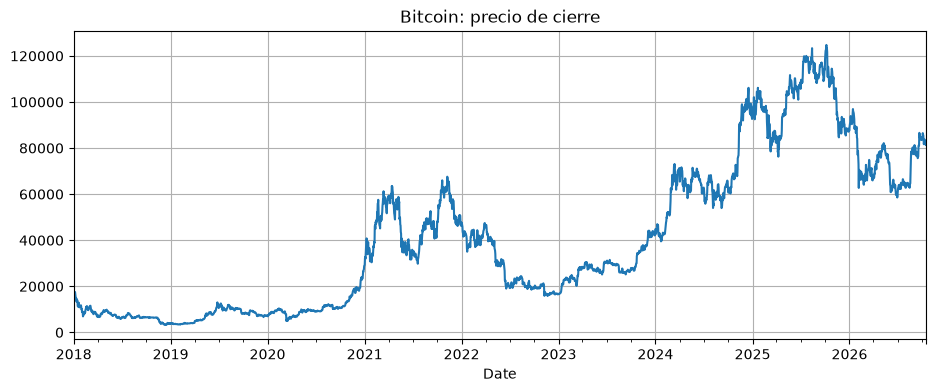

In [ ]:
inicio, fin = "2018-01-01", "2026-10-18"
simbolos = ["BTC-USD", "ETH-USD", "USDT-USD", "BNB-USD", "SOL-USD"]
series = [obtener_cierre(s, inicio, fin) for s in simbolos]
cripto = pd.concat(series, axis=1).sort_index()
display(cripto.head(12))
display(cripto.isna().sum().rename("faltantes").to_frame())
cripto["BTC-USD"].plot(title="Bitcoin: precio de cierre")
plt.show()

## 2. Recuperación de la TRM
Se conserva la consulta a datos.gov.co. Primero revisamos los campos; después ordenamos y verificamos duplicados.

In [ ]:
from sodapy import Socrata
# Dataset utilizado en el cuaderno original. La disponibilidad y el esquema
# dependen del portal datos.gov.co.
with Socrata("www.datos.gov.co", None) as client:
    registros = client.get("mcec-87by", limit=10000)
trm_raw = pd.DataFrame.from_records(registros)
print("Columnas originales:", list(trm_raw.columns))
display(trm_raw.head())

Columnas originales: ['valor', 'unidad', 'vigenciadesde', 'vigenciahasta']


,valor,unidad,vigenciadesde,vigenciahasta
0,3156.32,COP,2026-10-20T00:00:00.000,2026-10-20T00:00:00.000
1,3174.67,COP,2026-10-17T00:00:00.000,2026-10-19T00:00:00.000
2,3170.46,COP,2026-10-16T00:00:00.000,2026-10-16T00:00:00.000
3,3197.65,COP,2026-10-15T00:00:00.000,2026-10-15T00:00:00.000
4,3181.74,COP,2026-10-14T00:00:00.000,2026-10-14T00:00:00.000


In [ ]:
# Se conservan nombres originales: NO se renombran por posición.
candidatas_fecha = [c for c in trm_raw if "hasta" in c.lower()]
candidatas_valor = [c for c in trm_raw if ("valor" in c.lower() or "trm" in c.lower())]
print("Posibles fechas:", candidatas_fecha)
print("Posibles valores:", candidatas_valor)
if not candidatas_fecha or not candidatas_valor:
    raise ValueError("Revisar columnas devueltas por la API antes de continuar")
fecha_col = candidatas_fecha[0]
valor_col = candidatas_valor[0]
trm = trm_raw[[fecha_col, valor_col]].copy()
trm[fecha_col] = pd.to_datetime(trm[fecha_col], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
trm[valor_col] = pd.to_numeric(trm[valor_col], errors="coerce")
trm = (trm.dropna().sort_values(fecha_col)
       .drop_duplicates(fecha_col, keep="last")
       .set_index(fecha_col)[valor_col].rename("TRM"))
display(trm.head())
print("Rango:", trm.index.min(), trm.index.max())

Posibles fechas: ['vigenciahasta']
Posibles valores: ['valor']


vigenciahasta
1991-12-02    643.42
1991-12-03    639.22
1991-12-04    635.70
1991-12-05    631.51
1991-12-06    627.16
Name: TRM, dtype: float64

Rango: 1991-12-02 00:00:00 2026-10-20 00:00:00


## 3. Frecuencia diaria: observar no es imputar
`asfreq("D")` crea una grilla diaria. Los días sin dato quedan como `NaN`.


,TRM observada,Último valor publicado (ffill),Interpolación lineal
vigenciahasta,,,
2024-09-01,NaN,4132.11,4146.21
2024-09-02,NaN,4132.11,4153.26
2024-09-03,4160.31,4160.31,4160.31
2024-09-04,4185.80,4185.80,4185.80
2024-09-05,4185.82,4185.82,4185.82
2024-09-06,4172.50,4172.50,4172.50
2024-09-07,NaN,4172.50,4164.93
2024-09-08,NaN,4172.50,4157.36
2024-09-09,4149.79,4149.79,4149.79


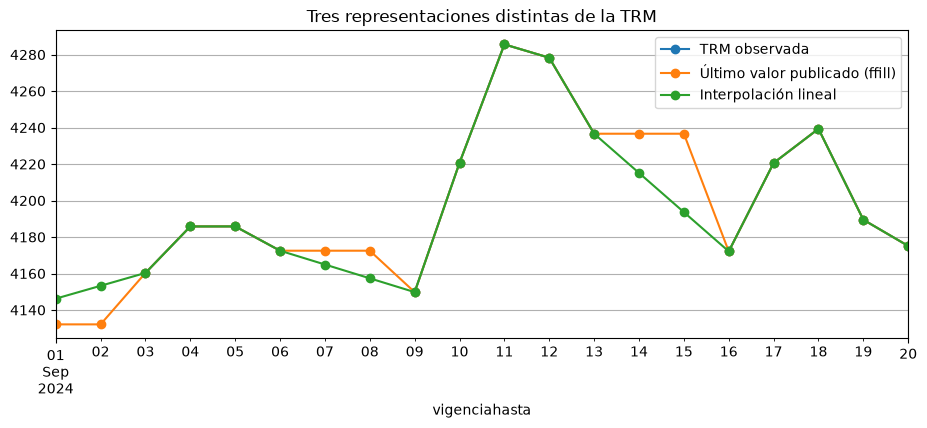

In [ ]:
trm_diaria = trm.asfreq("D")
trm_ultimo_publicado = trm_diaria.ffill()
trm_lineal = trm_diaria.interpolate(method="time", limit_area="inside")
ejemplo = pd.DataFrame({
    "TRM observada": trm_diaria,
    "Último valor publicado (ffill)": trm_ultimo_publicado,
    "Interpolación lineal": trm_lineal
})
display(ejemplo.loc["2024-09-01":"2024-09-20"])
ejemplo.loc["2024-09-01":"2024-09-20"].plot(
    marker="o", title="Tres representaciones distintas de la TRM"
)
plt.show()

## 4. Concatenar series con calendarios diferentes
Las criptomonedas suelen tener datos los siete días; la TRM no necesariamente. La concatenación externa (`join="outer"`) preserva las fechas de ambas fuentes.

Antes de unir, normalizamos el índice de fechas para evitar diferencias por huso horario. **No se imputan los precios de criptomonedas que todavía no existían.**

In [ ]:
datos_combinados = pd.concat(
    [cripto, trm.rename("TRM")], axis=1, join="outer"
).sort_index()
datos_combinados = datos_combinados.loc[inicio:fin]
display(datos_combinados.head(10))
display(datos_combinados.isna().sum().to_frame("faltantes"))
print("Índice:",type(datos_combinados.index).__name__)

C:\Users\000010478\AppData\Local\Temp\ipykernel_40732\2220806148.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  datos_combinados = pd.concat(


,BTC-USD,ETH-USD,USDT-USD,BNB-USD,SOL-USD,TRM
2018-01-01,13657.200195,772.640991,1.007280,8.414610,NaN,NaN
2018-01-02,14982.099609,884.443970,1.004900,8.837770,NaN,2984.00
2018-01-03,15201.000000,962.719971,1.013440,9.535880,NaN,2940.94
2018-01-04,15599.200195,980.921997,1.002530,9.213990,NaN,2908.68
2018-01-05,17429.500000,997.719971,0.998634,14.917200,NaN,2885.76
2018-01-06,17527.000000,1041.680054,1.008990,22.759800,NaN,NaN
2018-01-07,16477.599609,1153.170044,1.001570,18.656799,NaN,NaN
2018-01-08,15170.099609,1148.530029,1.009320,18.260900,NaN,NaN
2018-01-09,14595.400391,1299.739990,1.005990,17.411800,NaN,2898.32
2018-01-10,14973.299805,1255.819946,1.001280,17.390800,NaN,2914.37


,faltantes
BTC-USD,0
ETH-USD,0
USDT-USD,0
BNB-USD,0
SOL-USD,830
TRM,1128


Índice: DatetimeIndex


## 5. Días calendario frente a sesiones
Una serie regular en días calendario no es idéntica a una serie regular en sesiones de negociación. Los rezagos de un modelo ARIMA/SARIMA deben interpretarse en la escala elegida.

- Calendario diario: cada paso equivale a 24 horas; pueden existir `NaN`.
- Sesiones: cada paso equivale a una sesión observada; los festivos no ocupan posiciones.
- Propagación: crea valores derivados de una regla de imputación.

Para análisis descriptivo podemos comparar estas representaciones; para modelado predictivo debemos elegir una y mantenerla coherentemente.

In [ ]:
msft = obtener_cierre("MSFT", inicio, fin)
if len(msft):
    print("Observaciones reales:", len(msft))
    print("Fechas calendario:", len(msft.asfreq("D")))
    print("Faltantes calendario:", msft.asfreq("D").isna().sum())
    print("Sesiones consecutivas:",len(msft.dropna()))

Observaciones reales: 2210
Fechas calendario: 3210
Faltantes calendario: 1000
Sesiones consecutivas: 2210


## 6. Ejemplo meteorológico: Nueva York
El cuaderno original descargaba `NYC_weather.csv` y calculaba la temperatura media a partir de `TMIN` y `TMAX`.

La conversión de Fahrenheit a Celsius es:

$$
T_{^\circ C}=(T_{^\circ F}-32)\frac{5}{9}.
$$

Antes de interpretar estacionalidad climática conviene comprobar cobertura, unidad y valores ausentes.

,TMIN,TMAX,Celsius
DATE,,,
1869-01-01,19.0,29.0,-4.444444
1869-01-02,21.0,27.0,-4.444444
1869-01-03,27.0,35.0,-0.555556
1869-01-04,34.0,37.0,1.944444
1869-01-05,37.0,43.0,4.444444


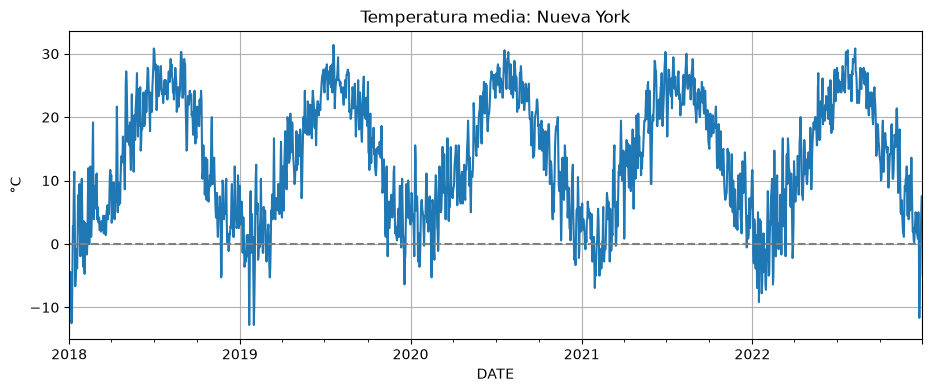

In [ ]:
url_clima = "https://robertohincapie.com/data/NYC_weather.csv"
try:
    clima = pd.read_csv(url_clima, parse_dates=["DATE"])
    clima = clima.set_index("DATE").sort_index()
    clima["Celsius"] = ((clima["TMIN"]+clima["TMAX"])/2 - 32)*5/9
    display(clima[["TMIN","TMAX","Celsius"]].head())
    clima.loc["2018-01-01":,"Celsius"].plot(title="Temperatura media: Nueva York")
    plt.axhline(0, linestyle="--", color="gray")
    plt.ylabel("°C")
    plt.show()
except Exception as e:
    print("Fuente meteorológica no disponible:",e)